<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_2_Regression/Projects/Instructions/Project.2-Housing/Housing-Pass-14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 2 - Pass 14: Housing Price Prediction






The project should be done using Regression prediction techniques ( with feature scaling and regularization ) as covered in class.
The goal is to minimize the RMS ***percentage*** error ( root mean squared percentage error - RMSPE ) on your prediction of the house sales price.



Any of the available features can be used in the regression, but a minimum set of variables that do the job should be the ultimate goal.



Be sure to go through the whole data science process and document as such in your Jupyter notebook.



This project will have less direct "To Do" guidance and the progression through the data science process will be more individualized this time around.  We will talk about all the issues during class so you're not going to be out on a ledge with this one, I just want to move you towards performing a data science project on your own eventually.

There are two parts to this data set, both of which are on AWS:

- [Housing Data Dictionary]( https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Housing%20-%20Data%20Documentation.pdf )
- [Data Set]( https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv)


In [1]:
! curl -s -I https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv

HTTP/1.1 200 OK
x-amz-id-2: nHENLLrynI1m2rqmGqwzvAjIOW4krc799gMlSW+aJQ3dSaSz1gFUNK4CBghz4UIKKk6TzjCNI1kF/czP8NNkHFHIHP6J33MJ
x-amz-request-id: MQZ8443D1R64WEK4
Server: AmazonS3
Date: Sat, 31 Oct 2026 13:55:48 GMT
Last-Modified: Fri, 06 Oct 2023 04:00:27 GMT
ETag: "76e84c9ee7f6fd4d51276697f81e76e1"
x-amz-server-side-encryption: AES256
Accept-Ranges: bytes
Content-Length: 880420
Content-Type: text/csv



In [2]:
! curl -s https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv | head -2

PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
905101070,20,RL,62.0,14299,Pave,,Reg,Lvl,AllPub,Inside,G

## Problem Definition

### Business Problem

Help investors evaluate whether what features might be a useful factor when assessing a property's potential market value.

### Data Science Problem

Supervised regression

## Data Collection/Sources

### Load Modules

In [3]:
# Import the libraries and modules
from IPython.display import Image

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
import statsmodels.api as sm

from sklearn import datasets, metrics, model_selection
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

### Load Data

In [4]:
# Define the data's url as 'url'
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'    # insert url here
url

'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

In [5]:
# Define the data frame as 'df'
df = pd.read_csv(url)

## Data Cleaning

### Overview

In [6]:
# Display the head - 81 columns
df.head()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400
1,905101330,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,Shed,500,10,2006,WD,Normal,90000
2,903454090,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,141000
3,533244030,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254000
4,909252020,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal,155000


In [7]:
# Display the tail - target is the last row
df.tail()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
2632,903231070,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal,114500
2633,906201021,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2009,WD,Normal,162000
2634,533253070,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2009,WD,Normal,211500
2635,527376100,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal,165000
2636,528292060,60,RL,41.0,12460,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2008,WD,Normal,225000


In [8]:
# See the shape - 2637 rows, 81 columns
df.shape

(2637, 81)

In [9]:
# See how many total entries
df.size

213597

### Summary Statistics

Summary statistics give you a quick overview of the data.  Some items to spot check:
- the Target:
  - look for nulls
    - null will be culled
  - look at min, max, median, and mean
    - is it a categorical field masquerading as a number?
- the Features:
  - numerical
    - look at min, max, median, and mean
      - a min=1 and max=count suggests an ID
  - categorical
    - look at unique and freq
      - freq=1, unique=count suggests an ID
      - freq=count suggests a meaningless feature

In [10]:
# Summary meta-data - our target 'SalePrice' is int64, our feature 'Lot Frontage' is float64
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 81 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   PID              2637 non-null   int64  
 1   MS SubClass      2637 non-null   int64  
 2   MS Zoning        2637 non-null   object 
 3   Lot Frontage     2188 non-null   float64
 4   Lot Area         2637 non-null   int64  
 5   Street           2637 non-null   object 
 6   Alley            180 non-null    object 
 7   Lot Shape        2637 non-null   object 
 8   Land Contour     2637 non-null   object 
 9   Utilities        2637 non-null   object 
 10  Lot Config       2637 non-null   object 
 11  Land Slope       2637 non-null   object 
 12  Neighborhood     2637 non-null   object 
 13  Condition 1      2637 non-null   object 
 14  Condition 2      2637 non-null   object 
 15  Bldg Type        2637 non-null   object 
 16  House Style      2637 non-null   object 
 17  Overall Qual  

In [11]:
# See the summary statistics
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
PID,2637.0,7.141301e+08,1.887527e+08,526301100.0,5.284770e+08,535453040.0,9.071870e+08,1.007100e+09
MS SubClass,2637.0,5.734926e+01,4.249909e+01,20.0,2.000000e+01,50.0,7.000000e+01,1.900000e+02
Lot Frontage,2188.0,6.916682e+01,2.335678e+01,21.0,5.800000e+01,68.0,8.000000e+01,3.130000e+02
Lot Area,2637.0,1.004469e+04,6.742550e+03,1300.0,7.436000e+03,9450.0,1.152600e+04,1.646600e+05
Overall Qual,2637.0,6.097459e+00,1.411522e+00,1.0,5.000000e+00,6.0,7.000000e+00,1.000000e+01
Overall Cond,2637.0,5.569966e+00,1.118262e+00,1.0,5.000000e+00,5.0,6.000000e+00,9.000000e+00
Year Built,2637.0,1.971289e+03,3.030699e+01,1872.0,1.954000e+03,1973.0,2.001000e+03,2.010000e+03
Year Remod/Add,2637.0,1.984203e+03,2.091308e+01,1950.0,1.965000e+03,1993.0,2.004000e+03,2.010000e+03
Mas Vnr Area,2614.0,1.018879e+02,1.795782e+02,0.0,0.000000e+00,0.0,1.640000e+02,1.600000e+03
BsmtFin SF 1,2636.0,4.384412e+02,4.496023e+02,0.0,0.000000e+00,368.0,7.320000e+02,5.644000e+03


### Nulls & Identifier Columns

#### Target Nulls


The target should be the first field that you look at.  Its data type will tell you what kind of machine learning problem this is ( classification or regression. ) Any nulls should be culled.  You can check for any skew in the data set.

In [12]:
# Define the name of the target column 'SalePrice' to work with it independently
target_col = 'SalePrice'
df[target_col]

,SalePrice
0,115400
1,90000
2,141000
3,254000
4,155000
...,...
2632,114500
2633,162000
2634,211500
2635,165000


In [13]:
# Look for nulls in the target 'SalePrice' (dropping rows if 20% nulls or under) - no nulls in the target
df[target_col].isnull().sum() / df[target_col].shape[0] * 100


np.float64(0.0)

#### Feature Nulls

In [16]:
# Define the name of the feature columns to work with them independently (all floats and integers are features)
# Select all float columns
feature_cols = df.select_dtypes(include=['object']).columns

# Drop the target column from the feature column names
feature_cols = feature_cols.drop(target_col, errors='ignore')

df[feature_cols].dtypes

,0
MS Zoning,object
Street,object
Alley,object
Lot Shape,object
Land Contour,object
Utilities,object
Lot Config,object
Land Slope,object
Neighborhood,object
Condition 1,object


In [17]:
# Look for nulls in the features (dropping rows if 20% nulls or under) - 17% is the highest proportion of nulls in 'Lot Frontage'
(df[feature_cols].isnull().sum() / df[feature_cols].shape[0] * 100).sort_values(ascending=False)

,0
Pool QC,99.582859
Misc Feature,96.359499
Alley,93.174061
Fence,79.977247
Mas Vnr Type,60.940463
Fireplace Qu,48.691695
Garage Cond,5.574516
Garage Qual,5.574516
Garage Finish,5.574516
Garage Type,5.498673


In [19]:
df[feature_cols]

,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition
0,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Feedr,...,Detchd,Unf,TA,TA,N,NaN,MnPrv,NaN,WD,Normal
1,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Norm,...,CarPort,Unf,TA,TA,Y,NaN,NaN,Shed,WD,Normal
2,RM,Pave,NaN,Reg,Bnk,AllPub,Inside,Gtl,IDOTRR,Norm,...,Detchd,Unf,TA,TA,P,NaN,NaN,NaN,WD,Normal
3,FV,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Somerst,Norm,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
4,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,SWISU,Feedr,...,Detchd,RFn,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,RM,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,BrkSide,Norm,...,Detchd,Unf,TA,TA,Y,NaN,MnPrv,Shed,WD,Normal
2633,RL,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,SawyerW,Feedr,...,Attchd,Unf,TA,TA,Y,NaN,NaN,NaN,WD,Normal
2634,RL,Pave,NaN,IR1,Lvl,AllPub,CulDSac,Gtl,Greens,Norm,...,Attchd,Fin,TA,TA,Y,NaN,NaN,NaN,WD,Normal
2635,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,...,Attchd,RFn,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal


#### Identifier Columns

In [40]:
# See proportion of unique values in the target column
(df[target_col].nunique() / df[target_col].shape[0] * 100) #.sort_values(ascending=False)

38.0873866446826

In [41]:
# See proportion of unique values in the feature columns - highest is 1%
(df[feature_cols].nunique() / df[feature_cols].shape[0] * 100).sort_values(ascending=False)

,0
Neighborhood,1.154163
Exterior 2nd,0.659522
Exterior 1st,0.577082
Sale Type,0.412201
Condition 1,0.370981
Functional,0.329761
House Style,0.329761
Roof Matl,0.329761
Condition 2,0.329761
BsmtFin Type 2,0.247321


In [42]:
# See the data types of the features - continuous are good for linear regression
df[feature_cols].dtypes.sort_values()

,0
MS Zoning,object
Bsmt Exposure,object
BsmtFin Type 1,object
BsmtFin Type 2,object
Heating,object
Heating QC,object
Central Air,object
Electrical,object
Bsmt Cond,object
Kitchen Qual,object


In [ ]:
# See the data types of the target - continuous are good for linear regression
df[target_col].dtypes

dtype('int64')

### Backup #1

In [20]:
# Make a backup
df_bak1 = df.copy()

In [27]:
# Restore from backup
df = df_bak1.copy()

### Cull the Nulls

If between 90% or greater, dropped columns.

If between 40-80%, imputed with the mode.

If between 1-10%, dropped the rows.

In [29]:
# Calculate the percentage of nulls in each feature column
null_percent = (df[feature_cols].isnull().sum() / df.shape[0] * 100).sort_values(ascending=False)

null_percent

,0
Fence,79.977247
Mas Vnr Type,60.940463
Fireplace Qu,48.691695
Garage Finish,5.574516
Garage Qual,5.574516
Garage Cond,5.574516
Garage Type,5.498673
Bsmt Exposure,2.882063
BsmtFin Type 2,2.806219
BsmtFin Type 1,2.768297


In [30]:
# Identify feature columns containing 90% or greater nulls
cols_to_drop = null_percent[null_percent >= 90].index

# Drop these columns from feature_cols
feature_cols = feature_cols.drop(cols_to_drop)

In [31]:
# Identify feature columns containing 40%-80% nulls
cols_to_impute = null_percent[(null_percent >= 40) & (null_percent <= 80)].index

# Impute nulls with the mode (most common categorical value)
for col in cols_to_impute:
    df[col] = df[col].fillna(df[col].mode()[0])

In [32]:
# Identify feature columns containing 1%-10% nulls
cols_to_drop_rows = null_percent[(null_percent >= 1) & (null_percent <= 10)].index

# Drop rows containing nulls in those feature columns
df = df.dropna(subset=cols_to_drop_rows).reset_index(drop=True)

In [33]:
# Verify rows dropped
df.shape

(2426, 81)

In [34]:
# Verify no nulls in feature columns
df[feature_cols].isnull().sum()

,0
MS Zoning,0
Street,0
Lot Shape,0
Land Contour,0
Utilities,0
Lot Config,0
Land Slope,0
Neighborhood,0
Condition 1,0
Condition 2,0


### Backup #2

In [35]:
# Make a backup
df_bak2 = df.copy()

In [36]:
# Restore from backup
df = df_bak2.copy()

In [37]:
# Verify the shape
df[feature_cols].shape

(2426, 40)

### Cleaned Data Frame

In [38]:
# Define our target and feature columns as a data frame to work with 'df_clean'
df_clean = pd.concat([df[target_col], df[feature_cols]], axis=1).reset_index(drop=True)

In [39]:
# Verify the working data frame
df_clean

,SalePrice,MS Zoning,Street,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Functional,Fireplace Qu,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Fence,Sale Type,Sale Condition
0,115400,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Feedr,...,Typ,Gd,Detchd,Unf,TA,TA,N,MnPrv,WD,Normal
1,141000,RM,Pave,Reg,Bnk,AllPub,Inside,Gtl,IDOTRR,Norm,...,Typ,Gd,Detchd,Unf,TA,TA,P,MnPrv,WD,Normal
2,254000,FV,Pave,IR1,Lvl,AllPub,Inside,Gtl,Somerst,Norm,...,Typ,TA,Attchd,RFn,TA,TA,Y,MnPrv,WD,Normal
3,155000,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,SWISU,Feedr,...,Typ,Gd,Detchd,RFn,TA,TA,Y,MnPrv,WD,Normal
4,125000,RL,Pave,Reg,Lvl,AllPub,FR2,Gtl,Sawyer,Feedr,...,Typ,Fa,Detchd,Unf,TA,TA,Y,MnPrv,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2421,114500,RM,Pave,Reg,Lvl,AllPub,Inside,Gtl,BrkSide,Norm,...,Typ,Gd,Detchd,Unf,TA,TA,Y,MnPrv,WD,Normal
2422,162000,RL,Pave,IR1,Lvl,AllPub,Inside,Gtl,SawyerW,Feedr,...,Typ,Gd,Attchd,Unf,TA,TA,Y,MnPrv,WD,Normal
2423,211500,RL,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,Greens,Norm,...,Typ,TA,Attchd,Fin,TA,TA,Y,MnPrv,WD,Normal
2424,165000,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,...,Typ,TA,Attchd,RFn,TA,TA,Y,MnPrv,WD,Normal


## EDA (Exploratory Data Analysis)

### Feature Selection

Use standard scaler to scale data set.

This data set is the cleaned without the feature selection from correlation.

In [43]:
# Convert categorical features into numeric columns
X_all_features = pd.get_dummies(df[feature_cols], drop_first=True, dtype=int)

# Define the target
y_target = df[target_col]

In [ ]:
# Specify values of alpha we want to try
alpha = [50, 75, 100, 200, 300, ]

# Create empty list to hold results
results_alpha = []

for a in alpha:
  # Calculate CV RMSE
  n = 200
  results = np.zeros(n)

  for idx in range(n):
    # Train, test split
    X_train, X_test, y_train, y_test = train_test_split(X_all_features, y_target, test_size=0.25)

    # Standard scale only training features
    scaler = StandardScaler()
    scaler.fit(X_train)
    X_train_scaled = scaler.transform(X_train)

    # Scale testing features
    X_test_scaled = scaler.transform(X_test)

    # Create the model
    model_lasso = Lasso(alpha = a, tol = .01, max_iter=10_000); # Looping through alpha

    # Fit regression
    model_lasso.fit(X_train_scaled, y_train)

    # Predict
    y_pred = model_lasso.predict(X_test_scaled)

    # Calculate and record performance metric
    results[idx] = np.sqrt(mean_squared_error(y_test,y_pred))

  results_alpha.append(results.mean())

results_df = pd.DataFrame({'Alpha': alpha, 'RMSE': results_alpha})


In [ ]:
results_df.sort_values( by = 'RMSE' )


,Alpha,RMSE
4,300,33489.692934
0,50,34305.175493
3,200,34487.449464
1,75,34660.335485
2,100,34794.041145


Get the Alpha that results in the lowest RMSE.

In [ ]:
results_df.sort_values( by = 'RMSE' )["Alpha"][0]


np.int64(50)

In [ ]:
results_df.sort_values( by = 'RMSE' )["Alpha"].iloc[0]


np.int64(300)

In [ ]:
a = results_df.sort_values( by = 'RMSE' )["Alpha"].iloc[0]
a

np.int64(300)

In [ ]:
# %%capture --no-stdout
# Perform CV
n = 500
results = np.zeros(n)

for idx in range(n):
  # Train, test split
  X_train, X_test, y_train, y_test = train_test_split(X_all_features, y_target, test_size=0.25)

  # Standard scale only training features
  scaler = StandardScaler()
  scaler.fit(X_train)
  X_train_scaled = scaler.transform(X_train)

  # Scale testing features
  X_test_scaled = scaler.transform(X_test)

  # Create the model
  model_lasso = Lasso(alpha = a, tol = .01, max_iter=10000)

  # Fit regression
  model_lasso.fit(X_train, y_train)

  # Predict
  y_pred = model_lasso.predict(X_test)

  # Calculate and record performance metric
  results[idx] = np.sqrt(mean_squared_error(y_test,y_pred))

print(f"CV RMSE: {results.mean().round(2)}")
print(f"Number of Predictors: {sum(model_lasso.coef_ >0)}")

CV RMSE: 34662.49
Number of Predictors: 25


In [ ]:
X_all_features.shape

(2033, 36)

In [ ]:
len(X_all_features.columns)

36

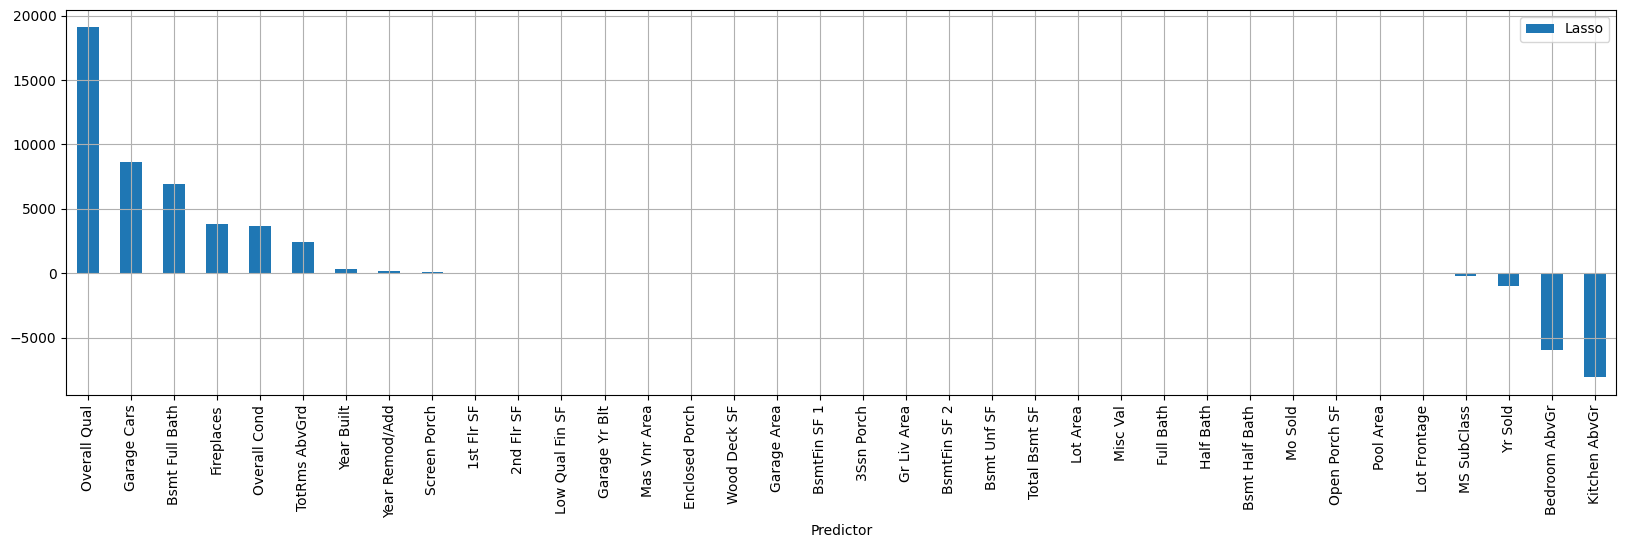

In [ ]:
# Plot model coefficients
model_results = pd.DataFrame()
model_results['Predictor'] = X_all_features.columns
model_results['Lasso'] = model_lasso.coef_
model_results.sort_values( by = ["Lasso"], ascending = False ).plot(
    x = 'Predictor',
    kind = 'bar',
    figsize = (20,5)
    )
plt.grid()

In [ ]:
model_results['Lasso'].abs().sort_values()

,Lasso
18,0.000000
19,0.000000
17,0.000000
34,0.000000
33,0.033518
2,0.252471
11,2.288753
10,3.112967
9,7.243484
15,7.758723


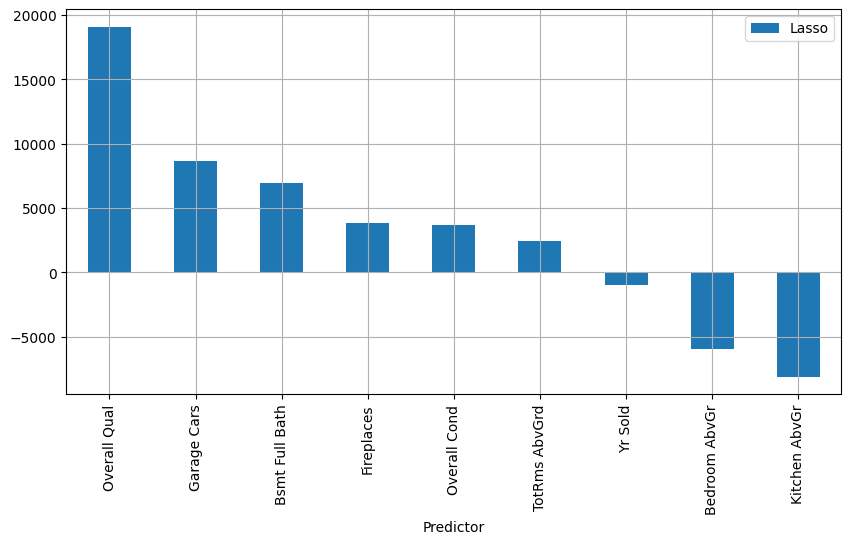

In [ ]:
# Plot parameters with coefficients greater than 0
greater_0 = model_results[(model_results['Lasso'] > 500 ) | (model_results['Lasso'] < -500 )]
greater_0.sort_values( by = ["Lasso"], ascending = False ).plot(x = 'Predictor', kind = 'bar', figsize = (10,5))
plt.grid()

In [ ]:
X_features_work = X_all_features[greater_0["Predictor"]]

### Working Data Frame

In [ ]:
df_work = pd.concat([df_clean[target_col], X_features_work], axis=1).reset_index(drop=True)

In [ ]:
df_work

,SalePrice,Overall Qual,Overall Cond,Bsmt Full Bath,Bedroom AbvGr,Kitchen AbvGr,TotRms AbvGrd,Fireplaces,Garage Cars,Yr Sold
0,115400,4,3,1.0,3,1,5,0,2.0,2007
1,90000,4,5,0.0,2,2,6,0,2.0,2006
2,141000,6,6,0.0,3,1,6,1,1.0,2007
3,254000,8,5,1.0,3,1,7,1,2.0,2010
4,155000,7,9,1.0,3,1,6,0,2.0,2009
...,...,...,...,...,...,...,...,...,...,...
2028,114500,6,6,0.0,3,1,6,1,2.0,2006
2029,162000,7,6,1.0,1,1,4,0,2.0,2009
2030,211500,8,5,1.0,1,1,4,2,2.0,2009
2031,165000,6,5,0.0,3,1,7,1,2.0,2009


## Data Processing

#### Performance

## Data Visualization

#### Residual Analysis

## Communication of Results

#### Conclusion

#### Future Work
